> **Bản PyTorch** của `examples/2. CNN + MLP/1_MNIST_CNN.ipynb` (Keras). Người chuyển: TV2 – Lê Phan Nguyên Hải. Notebook khuôn của BTL03.
>
> **Thay đổi so với bản Keras**

> - Ảnh Keras dạng `(N, 28, 28, 1)` (channels-last) → PyTorch `(N, 1, 28, 28)` (channels-first).
> - `Conv2D(filters, (3,3), padding='same', activation='relu')` → `nn.Conv2d(in, out, 3, padding=1)` + ReLU; PyTorch phải ghi rõ số kênh vào.
> - `MaxPooling2D((2,2))` → `nn.MaxPool2d(2)`; sau 3 lần pool: 28 → 14 → 7 → 3, nên `Flatten` ra 256·3·3 = 2304 (phải tự tính để khai báo `nn.Linear(2304, 512)`).
> - Các phần còn lại (loss, optimizer, fit/evaluate/predict) như khuôn `MNIST_MLP`.
> - Trích đặc trưng `fc2` và `pool3` + `GlobalAveragePooling2D` → hàm `model.features`, `model.conv_features(...).mean((2, 3))`.
> - Ô gốc `model.get_layer()` (gọi thiếu tham số, báo lỗi) được bỏ.

# Overview
- MNIST dataset
  + Goal: recognizing handwritten digits
  + Input: a 28x28 image
  + Output: class label (0, 1,..., 9)
- Defining an CNN+MLP for MNIST
- Training and evaluating an CNN+MLP

# Import libraries

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
# cuDNN mặc định chọn thuật toán nhanh nhưng không tất định -> chạy lại cùng seed vẫn ra số hơi khác.
# Tắt để mỗi lần Run All cho cùng kết quả (chậm hơn một chút).
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Keras tự dùng GPU nếu có; PyTorch phải chọn thiết bị và chuyển model, dữ liệu sang thiết bị đó
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')
from torchvision import datasets
import seaborn as sns
from sklearn.decomposition import PCA

torch 2.6.0+cu124 | device: cuda NVIDIA GeForce RTX 4060 Laptop GPU


# Hàm huấn luyện (thay cho `model.summary`, `model.fit`, `model.evaluate`, `model.predict`)
Keras có sẵn các hàm này; PyTorch thì tự viết vòng lặp. Mỗi notebook tự chứa các hàm dưới đây (chép từ khuôn), không phụ thuộc file code nào khác.

In [2]:
def summary(model, input_size):
    """Tương đương model.summary(): in tên lớp, kích thước đầu ra, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(
                lambda mod, inp, out, name=name: rows.append((name, type(mod).__name__, tuple(out.shape), sum(p.numel() for p in mod.parameters())))))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=device))
    for h in hooks:
        h.remove()
    print(f"{'Layer (type)':<36}{'Output Shape':<24}{'Param #':>10}")
    print('=' * 70)
    for name, typ, shape, n in rows:
        print(f"{name + ' (' + typ + ')':<36}{str((None,) + shape[1:]):<24}{n:>10,}")
    print('=' * 70)
    print(f"Total params: {sum(p.numel() for p in model.parameters()):,}")


def init_like_keras(model):
    """Keras khởi tạo Dense/Conv2D bằng glorot_uniform và bias = 0; PyTorch mặc định dùng kaiming_uniform.
    Khởi tạo giống Keras để kết quả sát bản gốc (nhất là khi đầu vào là pixel thô 0–255)."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)


def train_one_epoch(model, loader, loss_fn, optimizer):
    """Một epoch huấn luyện; trả về (loss, accuracy) trung bình trên tập train như Keras in ra."""
    model.train()                      # bật Dropout
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def evaluate(model, loader, loss_fn):
    """Tương đương model.evaluate(): trả về (loss, accuracy) trên cả tập."""
    model.eval()                       # tắt Dropout
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total_loss += loss_fn(logits, y).item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs):
    """Tương đương model.fit(..., validation_data=...): in mỗi epoch giống Keras, trả về history."""
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss, acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        for k, v in zip(history, (loss, acc, val_loss, val_acc)):
            history[k].append(v)
        print(f'Epoch {epoch}/{epochs} - {time.time() - t0:.1f}s - loss: {loss:.4f} - accuracy: {acc:.4f}'
              f' - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}')
    return history


def predict(model, x, batch_size=512):
    """Tương đương model.predict(): trả về xác suất softmax dạng numpy."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            xb = torch.as_tensor(np.asarray(x[i:i + batch_size]), dtype=torch.float32, device=device)
            out.append(torch.softmax(model(xb), dim=1).cpu().numpy())
    return np.concatenate(out)


def plot_history(history):
    """Vẽ loss/accuracy theo epoch từ history (Keras trả về History.history, ở đây là dict)."""
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, m in enumerate(['loss', 'accuracy']):
        ax[i].plot(range(1, len(history[m]) + 1), history[m], label='train')
        ax[i].plot(range(1, len(history['val_' + m]) + 1), history['val_' + m], label='validation')
        ax[i].set_xlabel('epoch'); ax[i].set_ylabel(m); ax[i].legend(); ax[i].grid(alpha=.3)
    plt.show()


def make_loader(x, y, batch_size, shuffle):
    """Mảng numpy -> DataLoader (thay cho việc truyền thẳng x, y vào model.fit)."""
    ds = TensorDataset(torch.tensor(np.asarray(x), dtype=torch.float32), torch.tensor(np.asarray(y), dtype=torch.long))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

In [3]:
num_classes = 10   # 10 classes: 0, 1,..., 9

# (1) Data

In [4]:
train_set = datasets.MNIST(root='../data', train=True, download=True)
test_set = datasets.MNIST(root='../data', train=False, download=True)
x_train, y_train = train_set.data.numpy(), train_set.targets.numpy()
x_test, y_test = test_set.data.numpy(), test_set.targets.numpy()

# Keras: reshape(60000, 28, 28, 1)  ->  PyTorch: (N, C, H, W) = (60000, 1, 28, 28)
x_train = x_train.reshape(60000, 1, 28, 28).astype('float32') / 255
x_test = x_test.reshape(10000, 1, 28, 28).astype('float32') / 255
print(x_train.shape[0], 'train samples')
print(x_test.shape[0], 'test samples')

60000 train samples
10000 test samples


In [5]:
# Keras dùng one-hot: to_categorical(2, num_classes=3) = [0, 0, 1]
# PyTorch: nn.CrossEntropyLoss nhận thẳng chỉ số lớp; one-hot chỉ để minh hoạ:
torch.nn.functional.one_hot(torch.tensor(2), num_classes=3)

tensor([0, 0, 1])

# (2) Declare model

In [6]:
class MnistCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # conv, pooling layers + dropout
        self.conv1 = nn.Conv2d(1, 64, kernel_size=3, padding=1)     # padding='same'
        self.pool1 = nn.MaxPool2d(2)
        self.conv_dropout1 = nn.Dropout(0.2)
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2)
        self.conv_dropout2 = nn.Dropout(0.2)
        self.conv3 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(2)
        self.conv_dropout3 = nn.Dropout(0.2)
        # similar to the MLP example!
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(256 * 3 * 3, 512)
        self.fc_dropout1 = nn.Dropout(0.2)
        self.fc2 = nn.Linear(512, 512)
        self.fc_dropout2 = nn.Dropout(0.2)
        self.fc3 = nn.Linear(512, num_classes)

    def conv_features(self, x):
        """Đầu ra lớp pool3, tương đương model.get_layer('pool3').output: (N, 256, 3, 3)."""
        x = self.conv_dropout1(self.pool1(torch.relu(self.conv1(x))))
        x = self.conv_dropout2(self.pool2(torch.relu(self.conv2(x))))
        return self.pool3(torch.relu(self.conv3(x)))

    def features(self, x):
        """Đầu ra lớp fc2 (sau ReLU), tương đương model.get_layer('fc2').output."""
        x = self.flatten(self.conv_dropout3(self.conv_features(x)))
        x = self.fc_dropout1(torch.relu(self.fc1(x)))
        return torch.relu(self.fc2(x))

    def forward(self, x):
        return self.fc3(self.fc_dropout2(self.features(x)))


model = MnistCNN(num_classes).to(device)
init_like_keras(model)
summary(model, (1, 28, 28))   # Keras: 1,817,610 tham số

Layer (type)                        Output Shape               Param #
conv1 (Conv2d)                      (None, 64, 28, 28)             640
pool1 (MaxPool2d)                   (None, 64, 14, 14)               0
conv_dropout1 (Dropout)             (None, 64, 14, 14)               0
conv2 (Conv2d)                      (None, 128, 14, 14)         73,856
pool2 (MaxPool2d)                   (None, 128, 7, 7)                0
conv_dropout2 (Dropout)             (None, 128, 7, 7)                0
conv3 (Conv2d)                      (None, 256, 7, 7)          295,168
pool3 (MaxPool2d)                   (None, 256, 3, 3)                0
conv_dropout3 (Dropout)             (None, 256, 3, 3)                0
flatten (Flatten)                   (None, 2304)                     0
fc1 (Linear)                        (None, 512)              1,180,160
fc_dropout1 (Dropout)               (None, 512)                      0
fc2 (Linear)                        (None, 512)                262,656
fc_dro

# (3) Train defined model
- Note that the training history including loss and accuracy will be save in 'history' variable
- In case your system runs out of memory (OOM), try to decrease batch size

**Keras → PyTorch:** `model.compile(loss='categorical_crossentropy', ...)` + lớp cuối `softmax` được thay bằng lớp cuối trả về *logits* và `nn.CrossEntropyLoss()` (đã gồm log-softmax). Vì vậy nhãn là số nguyên lớp, không cần one-hot (`to_categorical`). Keras mặc định trộn dữ liệu mỗi epoch → `shuffle=True` cho tập train.

In [7]:
loss_fn = nn.CrossEntropyLoss()
lr = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

batch_size = 128
epochs = 30
train_loader = make_loader(x_train, y_train, batch_size, shuffle=True)
test_loader = make_loader(x_test, y_test, batch_size, shuffle=False)

starting_time = time.time()
history = fit(model, train_loader, test_loader, loss_fn, optimizer, epochs)
print('> training time is %.4f minutes' % ((time.time() - starting_time) / 60))

Epoch 1/30 - 3.2s - loss: 2.0643 - accuracy: 0.2920 - val_loss: 0.9658 - val_accuracy: 0.7110


Epoch 2/30 - 3.0s - loss: 0.7533 - accuracy: 0.7494 - val_loss: 0.2989 - val_accuracy: 0.9104


Epoch 3/30 - 3.0s - loss: 0.3883 - accuracy: 0.8754 - val_loss: 0.1795 - val_accuracy: 0.9455


Epoch 4/30 - 3.1s - loss: 0.2706 - accuracy: 0.9145 - val_loss: 0.1356 - val_accuracy: 0.9581


Epoch 5/30 - 3.2s - loss: 0.2174 - accuracy: 0.9317 - val_loss: 0.1123 - val_accuracy: 0.9634


Epoch 6/30 - 3.0s - loss: 0.1887 - accuracy: 0.9401 - val_loss: 0.0959 - val_accuracy: 0.9689


... (20 outputs left out)

Epoch 27/30 - 3.1s - loss: 0.0695 - accuracy: 0.9778 - val_loss: 0.0350 - val_accuracy: 0.9875


Epoch 28/30 - 3.0s - loss: 0.0669 - accuracy: 0.9789 - val_loss: 0.0334 - val_accuracy: 0.9882


Epoch 29/30 - 3.1s - loss: 0.0649 - accuracy: 0.9795 - val_loss: 0.0336 - val_accuracy: 0.9884


Epoch 30/30 - 3.1s - loss: 0.0625 - accuracy: 0.9801 - val_loss: 0.0325 - val_accuracy: 0.9887
> training time is 1.5422 minutes


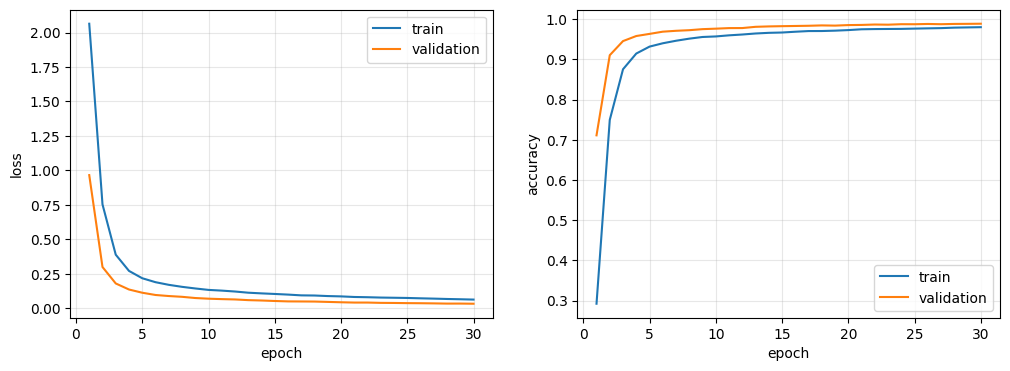

In [8]:
plot_history(history)

### Training time
- Bản Keras gốc (GPU trên Colab): 3.3867 phút cho 30 epoch, test accuracy 0.9884
- Bản PyTorch: xem kết quả ô trên (RTX 4060 Laptop)

# (4) Evaluate trained model

In [9]:
score = evaluate(model, test_loader, loss_fn)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.03246988166566007
Test accuracy: 0.9887


### PCA trên ảnh gốc

(60000, 784) (60000,)


(60000, 2)


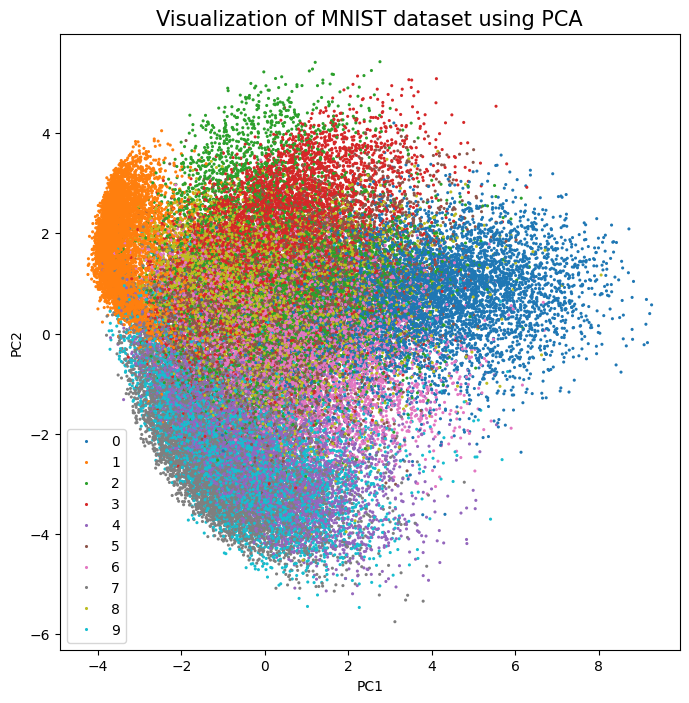

In [10]:
data_org = x_train.reshape(x_train.shape[0], -1)
data_lbl = y_train
print(data_org.shape, data_lbl.shape)

def plot_pca(feat, title):
    p = PCA(n_components=2).fit_transform(feat)
    print(p.shape)
    plt.figure(figsize=(8, 8))
    # legend='full' + palette 'tab10': hiện đủ 10 chữ số (mặc định seaborn coi nhãn là số liên tục, chỉ hiện vài mốc)
    sns.scatterplot(x=p[:, 0], y=p[:, 1], hue=data_lbl, palette='tab10', legend='full', s=5, linewidth=0)
    plt.xlabel('PC1'); plt.ylabel('PC2')
    plt.title(title, {'fontsize': 15})
    plt.show()

plot_pca(data_org, 'Visualization of MNIST dataset using PCA')

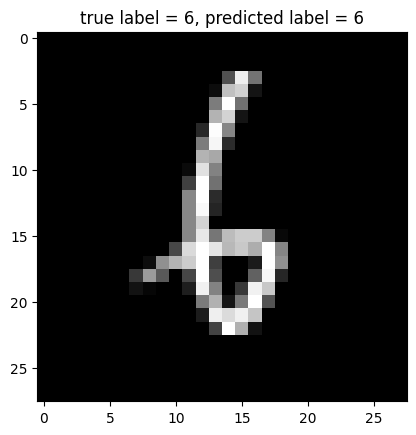

In [11]:
# select a test image randomly
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = y_test[random_test_index]
pred_label = np.argmax(predict(model, np.expand_dims(test_img, axis=0)))

plt.imshow(test_img[0], cmap='gray')     # Keras: test_img[:, :, 0]; PyTorch: kênh nằm ở chiều 0
plt.title('true label = %d, predicted label = %d' % (test_label, pred_label))
plt.show()

### PCA trên đặc trưng `fc2`
Keras: `Model(model.input, model.get_layer('fc2').output).predict(x_train)`. PyTorch: chạy `model.features` theo từng batch.

(60000, 512)
(60000, 2)


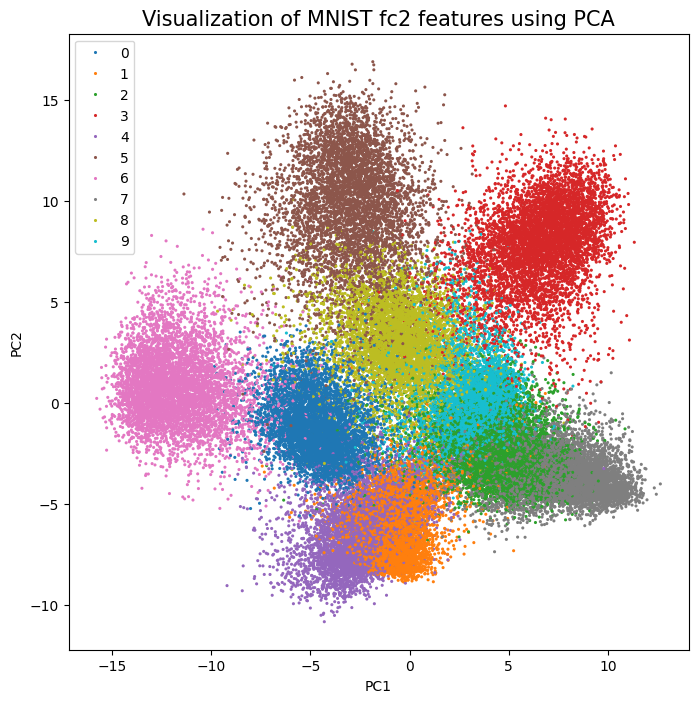

In [12]:
def extract(fn, x, batch_size=1000):
    """Chạy một hàm trích đặc trưng của model trên toàn bộ x theo batch, trả về numpy."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            out.append(fn(torch.as_tensor(x[i:i + batch_size], device=device)).cpu().numpy())
    return np.concatenate(out)

y_feat = extract(model.features, x_train)
print(y_feat.shape)
plot_pca(y_feat, 'Visualization of MNIST fc2 features using PCA')

### PCA trên `pool3` + Global Average Pooling
Keras: `GlobalAveragePooling2D()(model.get_layer('pool3').output)`. PyTorch: lấy trung bình theo chiều H, W.

(60000, 256)
(60000, 2)


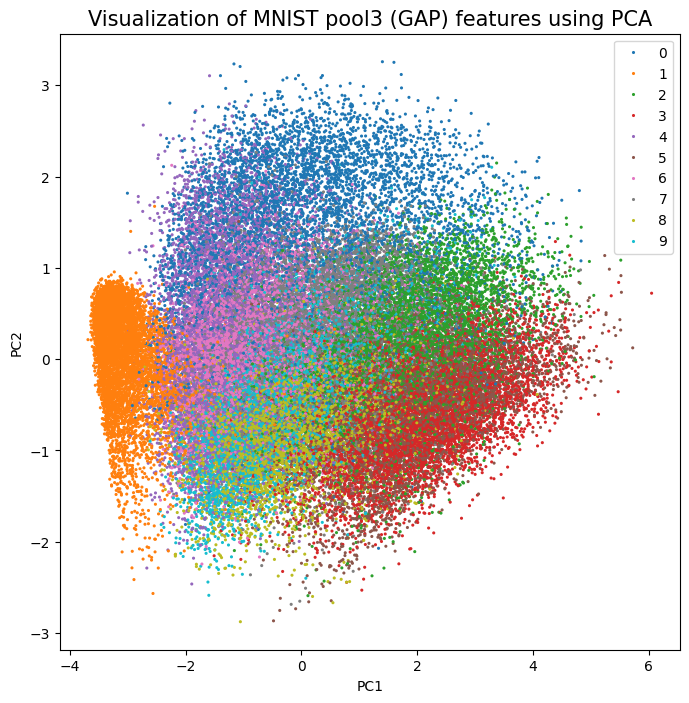

In [13]:
y2_feat = extract(lambda x: model.conv_features(x).mean(dim=(2, 3)), x_train)
print(y2_feat.shape)
plot_pca(y2_feat, 'Visualization of MNIST pool3 (GAP) features using PCA')